# Ignition Delay of a Hydrogen/Oxygen Mixture: Active Subspaces of a 19-Reaction Kinetic Mechanism

__Manav Vohra__, Department of Civil and Environmental Engineering, Vanderbilt University, Nashville, TN

__Alen Alexanderian__, Department of Mathematics, North Carolina State University, Raleigh, NC

__Hayley Guy__, Department of Mathematics, North Carolina State University, Raleigh, NC

__Sankaran Mahadevan__, Department of Civil and Environmental Engineering, Vanderbilt University, Nashville, TN

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

The notebook runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library (version 1.0 or later) and reads the shipped data files. In the repository's terms this is a **stored-data** set: the data were computed with [Cantera](https://cantera.org) 3.2.0, an outside code, by the included `generate_data.py`, and the shipped files are the record, with full provenance in `DATA.md`. Cantera is needed only to regenerate them.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import h2o2_ignition_model as hm   # names, nominal values and bounds (numpy only); solving needs Cantera

SEED = 2019                        # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
lab19 = [f'$A_{{{i}}}$' for i in range(1, 20)]
lab36 = lab19 + [f'$E_{{a,{i}}}$' for i in hm.EA_SET] + ['$P_0$', '$T_0$', r'$\phi$']

### Summary

Vohra et al. [[1]][R1] compute active subspaces of the ignition delay of a fuel-rich H$_2$/O$_2$ mixture ($\phi_0 = 2$, 1 atm, 900 K) with respect to the uncertain rate parameters of a 19-reaction mechanism: 19 log pre-exponential factors, and 36 inputs when activation energies and the initial state are added. They find that one direction captures the variability. We rebuild the study in Cantera with the same reactions and ranges but the Li et al. (2004) rate constants (the paper's Yetter et al. (1991) values are not printed), and estimate the subspaces from 1000 Monte Carlo samples with finite-difference gradients in each case. The ranking of inputs matches the paper's: $A_9$, $A_1$, $A_{15}$ and $A_{17}$ for 19 inputs, and $A_9$, $T_0$, $A_1$, $A_{15}$, $A_{17}$ and $E_{a,15}$ for 36. But $\lambda_1/\lambda_2$ is only 6.7 and 9.6, with a second, sharper gap after $\lambda_2$ ($\lambda_2/\lambda_3$ = 56 and 107). The ignition delay switches between a slow branch (tens to hundreds of ms) and a fast one (about 0.1–1 ms, 23 % of the 19-input samples) as $k_1$ overtakes $k_9$, which a one-dimensional quadratic captures only to a leave-one-out $R^2$ of 0.90–0.93.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs, normalized to $\mathbf x\in[-1,1]^m$ with the uniform density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend and a low-degree polynomial in $\mathbf y$ can stand in for $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

A homogeneous H$_2$/O$_2$ mixture ignites adiabatically at constant pressure $P_0$ [1, p. 153]. With mass fractions $Y_k$, molar production rates $\dot\omega_k$, molar masses $W_k$, molar enthalpies $h_k$, density $\rho$ and specific heat $c_p$,

$$
\frac{dY_k}{dt} = \frac{W_k\,\dot\omega_k}{\rho},\qquad
\frac{dT}{dt} = -\frac{1}{\rho\,c_p}\sum_k h_k\,\dot\omega_k,\qquad
k_i(T) = A_i\,T^{n_i}\exp\!\left(-\frac{E_{a,i}}{RT}\right)\quad(\text{paper Eq. 1}),
$$

where the $\dot\omega_k$ come from the 19 reversible reactions R1–R19 of the paper's Table 1 (listed below). The initial state is $T_0 = 900$ K, $P_0 = 1$ atm and equivalence ratio $\phi_0 = 2$ (paper Eq. 4: H$_2$ : O$_2$ = $2\phi$ : 1 by moles; the paper names no diluent, and we use none). The quantity of interest is the **ignition delay** $\tau$. The paper defines it as the time at which the rate of temperature increase exceeds "a given threshold" without giving the threshold; we use the time at which $T$ first reaches $T_0 + 400$ K. On the slow branch, which holds most of the samples, this differs from thresholds of 200 or 800 K by less than $5\times10^{-5}$ relative. On the fast branch it differs by about 1 % (`DATA.md`).

**Mechanism.** The paper used the rate parameters of Yetter, Dryer and Rabitz [3] in TChem; those values are not printed in the paper, and we could not obtain them. We use the same 19 reactions, in the same order (R4 written the other way round; see below), with the rate parameters of Li et al. [2, Table I] (cm–mol–s–kcal units, as printed), which descend from [3] through Mueller et al. (1999). R9 and R15 are pressure-dependent (Troe) in [2], and R14 and R19 are sums of two Arrhenius expressions. Thermodynamic data are GRI-Mech 3.0's [6]. The mechanism file `h2o2_li2004.yaml` is solved with Cantera 3.2.0 [5] (CVODES, rtol $10^{-9}$, atol $10^{-18}$). **This is the main departure from the paper**, and it changes the numbers (see the comparison).

**Uncertain inputs.** These follow the paper [1, Secs. 4–5]. All are independent and uniform.
- 19-input case: $\ln A_i \sim U[0.97\ln A_i^*, 1.03\ln A_i^*]$, $A$ in cm–mol–s units, $i = 1,\dots,19$. The width of this interval depends on the units of $A$ (not on the base of the logarithm): it multiplies $k_i$ by a factor of up to $(A_i^*)^{0.03}$, between 1.38 and 4.8 here (table below). For a reaction with two Arrhenius expressions, $A_i^*$ is the first one listed in [2] (the low-pressure limit for R9 and R15), and every expression of R$i$ is scaled by $A_i/A_i^*$. For R9 this convention widens the range: the low-pressure $A_9^* = 6.37\times10^{20}$ gives a factor of up to 4.21 on $k_9$ ($\pm1.437$ in $\ln k_9$), where the high-pressure $A = 1.48\times10^{12}$ would give 2.32 ($\pm0.841$). This adds to the fast-ignition branch described after the data are loaded.
- 36-input case: $\ln A_i$ ($\pm 2$ %), the 14 activation energies with nonzero nominal value ($\pm 2$ %, every expression of the reaction scaled by $E_{a,i}/E_{a,i}^*$), and $P_0$, $T_0$, $\phi_0$ ($\pm 2$ %). In [2] the reactions with zero $E_a$ are R6, R7, R8 and R12, plus the first expression of R19. In [3] they were R6–R9 and R13 [1, p. 158]. So our 14 are R1–R5, R9, R10, R11, R13–R18. The paper's 14 had R12 and R19 instead of R9 and R13. The count, 19 + 14 + 3 = 36, is the paper's.

**R4 is written the other way round.** The paper's Table 1 lists R4 as OH + OH → O + H$_2$O. The mechanism file follows Li et al. and writes it O + H$_2$O ⇌ 2 OH, so $A_4^*$ and $E_{a,4}^*$, and the perturbed $\ln A_4$ and $E_{a,4}$, belong to that direction. Cantera computes the reverse rate from the equilibrium constant, so a multiplier on $A_4$ scales both directions alike; only the nominal values, and hence the widths of the ranges, depend on the written direction. It does not matter here, because R4 barely affects $\tau$: $\mathbb E[(\partial\tau/\partial x_i)^2]/\lambda_1$ (normalized inputs) is $2\times10^{-13}$ for $\ln A_4$ with 19 inputs, and $9\times10^{-14}$ and $1\times10^{-13}$ for $\ln A_4$ and $E_{a,4}$ with 36 (printed below), so even a range several times wider would leave the results unchanged.

The table is printed from `h2o2_ignition_model.py`.

In [2]:
print(f"{'input':6s} {'reaction':26s} {'A* (cm-mol-s)':>13s} {'ln A*':>8s} "
      f"{'19-input range of ln A':>22s} {'factor on k':>11s} {'36-input range of ln A':>22s}")
for i in range(19):
    print(f'lnA{i + 1:<3d} {hm.REACTIONS[i]:26s} {hm.A_REF[i]:13.3e} {hm.LNA_REF[i]:8.3f} '
          f'[{hm.LOWER19[i]:8.3f}, {hm.UPPER19[i]:8.3f}] {np.exp(0.03 * hm.LNA_REF[i]):11.2f} '
          f'[{hm.LOWER36[i]:8.3f}, {hm.UPPER36[i]:8.3f}]')
print(f"\n{'input':6s} {'reaction':26s} {'Ea* (kcal/mol)':>14s}  36-input range")
for k, r in enumerate(hm.EA_SET):
    j = 19 + k
    print(f'Ea{r:<4d} {hm.REACTIONS[r - 1]:26s} {hm.EA_REF[r - 1]:14.2f}  [{hm.LOWER36[j]:.4f}, {hm.UPPER36[j]:.4f}]')
for j, (n, u) in enumerate(zip(hm.NAMES36[-3:], hm.UNITS36[-3:])):
    print(f'{n:6s} {u:26s} {hm.NOMINAL36[33 + j]:14.2f}  [{hm.LOWER36[33 + j]:.4f}, {hm.UPPER36[33 + j]:.4f}]')
print(f'\nm = {len(hm.NAMES19)} (pre-exponentials) and m = {len(hm.NAMES36)} (pre-exponentials, '
      f'activation energies, initial state); ignition at T = T0 + {hm.T_RISE:g} K')

input  reaction                   A* (cm-mol-s)    ln A* 19-input range of ln A factor on k 36-input range of ln A
lnA1   H + O2 <=> O + OH              3.550e+15   35.806 [  34.732,   36.880]        2.93 [  35.090,   36.522]
lnA2   O + H2 <=> H + OH              5.080e+04   10.836 [  10.511,   11.161]        1.38 [  10.619,   11.052]
lnA3   H2 + OH <=> H2O + H            2.160e+08   19.191 [  18.615,   19.767]        1.78 [  18.807,   19.575]
lnA4   O + H2O <=> 2 OH               2.970e+06   14.904 [  14.457,   15.351]        1.56 [  14.606,   15.202]
lnA5   H2 + M <=> 2 H + M             4.580e+19   45.271 [  43.913,   46.629]        3.89 [  44.365,   46.176]
lnA6   2 O + M <=> O2 + M             6.160e+15   36.357 [  35.266,   37.448]        2.98 [  35.630,   37.084]
lnA7   O + H + M <=> OH + M           4.710e+18   42.996 [  41.706,   44.286]        3.63 [  42.136,   43.856]
lnA8   H + OH + M <=> H2O + M         3.800e+22   51.992 [  50.432,   53.552]        4.76 [  50.952,   53.03

### Load data

`generate_data.py` drew three independent Monte Carlo samples (uniform on the boxes above, seeds 2019019, 2019036 and 2019100), ran the Cantera model at each point, and wrote the physical inputs, the ignition delay $\tau$ in seconds, and, for the first two sets, the gradient of $\tau$ with respect to the physical inputs by central differences (step $10^{-3}$ of each input's half-range; checked in `DATA.md`). The third set (10 000 points, $\tau$ only) plays the role of the paper's cross-validation set (Table 2, Fig. 6).

In [3]:
X19 = np.loadtxt('inputs_19.csv', delimiter=',')        # (1000, 19) ln A_i, A in cm-mol-s units
f19 = np.loadtxt('outputs_19.csv', delimiter=',')       # (1000,) ignition delay tau, s
G19 = np.loadtxt('gradients_19.csv', delimiter=',')     # (1000, 19) dtau/dlnA_i, s
X36 = np.loadtxt('inputs_36.csv', delimiter=',')        # (1000, 36) physical inputs (hm.NAMES36)
f36 = np.loadtxt('outputs_36.csv', delimiter=',')       # (1000,) tau, s
G36 = np.loadtxt('gradients_36.csv', delimiter=',')     # (1000, 36) dtau/dx_j in physical units
Xmc = np.loadtxt('mc_inputs_36.csv', delimiter=',')     # (10000, 36) further samples, tau only
fmc = np.loadtxt('mc_outputs_36.csv', delimiter=',')    # (10000,) tau, s
for n, a in [('X19', X19), ('f19', f19), ('G19', G19), ('X36', X36), ('f36', f36), ('G36', G36),
             ('Xmc', Xmc), ('fmc', fmc)]:
    print(f'{n:4s} {a.shape}')

X19  (1000, 19)
f19  (1000,)
G19  (1000, 19)
X36  (1000, 36)
f36  (1000,)
G36  (1000, 36)
Xmc  (10000, 36)
fmc  (10000,)


We check the samples against the declared uniform boxes (range, kurtosis, duplicates). We check the gradient coordinates by comparing the least-squares slope of $\tau$ on the normalized inputs with the mean normalized gradient (they agree when the gradients are taken in the stated coordinates and scaled once). We also print the distribution of $\tau$.

In [4]:
def normalize(X, lo, up):
    return 2 * (X - lo) / (up - lo) - 1

for name, X, f, G, lo, up in [('19', X19, f19, G19, hm.LOWER19, hm.UPPER19),
                              ('36', X36, f36, G36, hm.LOWER36, hm.UPPER36)]:
    Z = normalize(X, lo, up)
    kurt = np.mean((Z - Z.mean(0))**4, 0) / Z.var(0)**2
    Gn = G * (up - lo) / 2                                   # gradient in normalized coordinates
    b = np.linalg.lstsq(np.column_stack([np.ones(len(Z)), Z]), f, rcond=None)[0][1:]
    gbar = Gn.mean(0)
    print(f'{name}-input set: normalized inputs in [{Z.min():.4f}, {Z.max():.4f}], kurtosis '
          f'{kurt.min():.2f}-{kurt.max():.2f} (uniform 1.8); duplicate rows {len(X) - len(np.unique(X, axis=0))}')
    print(f'   OLS slope of tau on normalized inputs vs mean normalized gradient: cosine '
          f'{b @ gbar / np.linalg.norm(b) / np.linalg.norm(gbar):.3f}, norms {np.linalg.norm(b):.4f} '
          f'and {np.linalg.norm(gbar):.4f} s')
Zmc = normalize(Xmc, hm.LOWER36, hm.UPPER36)
print(f'MC set: normalized inputs in [{Zmc.min():.4f}, {Zmc.max():.4f}]')
neg_Ea = np.sum(X36[:, 19:33] * hm.EA_REF[np.array(hm.EA_SET) - 1] <= 0)
print(f'samples outside physical meaning (A <= 0, Ea of the wrong sign, P0, T0 or phi <= 0): '
      f'{neg_Ea + np.sum(X36[:, 33:] <= 0)}')
for name, f in [('19-input', f19), ('36-input', f36), ('36-input MC', fmc)]:
    q = np.percentile(f, [0, 2.5, 50, 97.5, 100])
    print(f'{name:12s} tau: min {q[0]*1e3:.3f} ms, 2.5 % {q[1]*1e3:.3f} ms, median {q[2]*1e3:.1f} ms, '
          f'97.5 % {q[3]*1e3:.0f} ms, max {q[4]*1e3:.0f} ms; mean {f.mean()*1e3:.1f} ms, sd {f.std(ddof=1)*1e3:.1f} ms; '
          f'below 1 ms: {np.sum(f < 1e-3)} of {f.size}')

19-input set: normalized inputs in [-1.0000, 1.0000], kurtosis 1.72-1.88 (uniform 1.8); duplicate rows 0
   OLS slope of tau on normalized inputs vs mean normalized gradient: cosine 0.993, norms 0.1985 and 0.1868 s
36-input set: normalized inputs in [-0.9999, 1.0000], kurtosis 1.72-1.88 (uniform 1.8); duplicate rows 0
   OLS slope of tau on normalized inputs vs mean normalized gradient: cosine 0.992, norms 0.1727 and 0.1653 s
MC set: normalized inputs in [-1.0000, 1.0000]
samples outside physical meaning (A <= 0, Ea of the wrong sign, P0, T0 or phi <= 0): 0
19-input     tau: min 0.109 ms, 2.5 % 0.135 ms, median 68.4 ms, 97.5 % 475 ms, max 864 ms; mean 111.7 ms, sd 133.6 ms; below 1 ms: 226 of 1000
36-input     tau: min 0.130 ms, 2.5 % 0.231 ms, median 79.6 ms, 97.5 % 415 ms, max 688 ms; mean 107.7 ms, sd 112.2 ms; below 1 ms: 114 of 1000
36-input MC  tau: min 0.119 ms, 2.5 % 0.238 ms, median 77.1 ms, 97.5 % 399 ms, max 926 ms; mean 106.7 ms, sd 110.9 ms; below 1 ms: 1239 of 10000


All inputs are physically meaningful: every $A_i > 0$, every scaled $E_a$ keeps its sign, and $P_0, T_0, \phi_0 > 0$. In both sets the normalized inputs fill $[-1, 1]$ with uniform kurtosis (1.72–1.88), and there are no duplicate rows. The least-squares slope and the mean gradient point the same way (cosine 0.993 and 0.992). The distribution of $\tau$ is **bimodal**. Most samples ignite slowly, through the HO$_2$/H$_2$O$_2$ chain (median 68.4 ms for 19 inputs, 77.1 ms on the 10 000-sample set). But 226 of the 1000 19-input samples, and 1239 of the 10 000 36-input samples, ignite in 0.11–1 ms. At 900 K and 1 atm the mixture sits near the second explosion limit, where chain branching (R1, H + O$_2$ → O + OH) competes with chain termination (R9, H + O$_2$ + M → HO$_2$ + M). The next cell shows that the switch is governed by $\ln(k_1/k_1^*) - \ln(k_9/k_9^*)$: no sample with a difference below 0.5 is on the fast branch, every sample above 1.0 is, and 20.6 % of those in between are. Applied to the input ranges, this rule predicts a fast fraction of 0.214 (observed: 0.226). Had $A_9^*$ been R9's high-pressure $A$, with its narrower range on $\ln k_9$, the rule would predict 0.149. So the wide R9 range adds to the fast branch, but most of it comes from where the Li et al. nominal point sits relative to the explosion limit.

In [5]:
d19 = (X19[:, 0] - hm.LNA_REF[0]) - (X19[:, 8] - hm.LNA_REF[8])     # ln(k1/k1*) - ln(k9/k9*)
fast = f19 < 1e-3
print(f'19-input set: ln(k1/k1*) - ln(k9/k9*) is {d19[fast].mean():+.2f} on average in the {fast.sum()} '
      f'samples with tau < 1 ms and {d19[~fast].mean():+.2f} in the other {(~fast).sum()}; its range is '
      f'[{d19.min():.2f}, {d19.max():.2f}]')
for lo_, hi_ in [(-3, -1), (-1, 0), (0, 0.5), (0.5, 1), (1, 3)]:
    s = (d19 >= lo_) & (d19 < hi_)
    print(f'   {lo_:+.1f} <= difference < {hi_:+.1f}: {s.sum():4d} samples, {np.mean(fast[s]) * 100:5.1f} % with tau < 1 ms')
# The same rule applied to the input ranges: ln(k1/k1*) and ln(k9/k9*) are independent and uniform on
# +/- 0.03 ln A*, so the expected fast fraction is P(d > 1) + (fraction above) * P(0.5 < d < 1).
mid = np.mean(fast[(d19 >= 0.5) & (d19 < 1.0)])
def p_fast(a1, a9, n=400001):
    u1 = np.linspace(-a1, a1, n)                                   # ln(k1/k1*), uniform grid
    p_gt = lambda c: np.mean(np.clip((u1 - c + a9) / (2 * a9), 0, 1))   # P(u1 - u9 > c)
    return p_gt(1.0) + mid * (p_gt(0.5) - p_gt(1.0))
A9_INF = 1.48e12      # R9 high-pressure-limit A in h2o2_li2004.yaml, cm^3/(mol s)
a1 = 0.03 * hm.LNA_REF[0]
for label, a9 in [('A9* = low-pressure A (as built)', 0.03 * hm.LNA_REF[8]),
                  ('A9* = high-pressure A (alternative)', 0.03 * np.log(A9_INF))]:
    print(f'{label:36s}: ln(k9/k9*) in +/-{a9:.3f} (factor {np.exp(a9):.2f}); '
          f'rule predicts a fast fraction of {p_fast(a1, a9):.3f}')
print(f'observed fast fraction: {fast.mean():.3f} (ln(k1/k1*) in +/-{a1:.3f})')

19-input set: ln(k1/k1*) - ln(k9/k9*) is +1.41 on average in the 226 samples with tau < 1 ms and -0.40 in the other 774; its range is [-2.36, 2.34]
   -3.0 <= difference < -1.0:  186 samples,   0.0 % with tau < 1 ms
   -1.0 <= difference < +0.0:  305 samples,   0.0 % with tau < 1 ms
   +0.0 <= difference < +0.5:  160 samples,   0.0 % with tau < 1 ms
   +0.5 <= difference < +1.0:  155 samples,  20.6 % with tau < 1 ms
   +1.0 <= difference < +3.0:  194 samples, 100.0 % with tau < 1 ms
A9* = low-pressure A (as built)     : ln(k9/k9*) in +/-1.437 (factor 4.21); rule predicts a fast fraction of 0.214
A9* = high-pressure A (alternative) : ln(k9/k9*) in +/-0.841 (factor 2.32); rule predicts a fast fraction of 0.149
observed fast fraction: 0.226 (ln(k1/k1*) in +/-1.074)


### Estimate the subspace

The gradients are available (central differences, accurate to about $10^{-5}$ relative; `DATA.md`), so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i\nabla f_i\nabla f_i^T$. All inputs are uniform, so `ac.Uniform(lower, upper)` scales every input the same way, by its half-range, onto $[-1,1]$. We pass the physical inputs and the physical gradients, and the library normalizes both once. We use 500 bootstrap replicates (seed 2019). We fix $n = 1$ as the paper does, and also print the dimension that the library's eigenvalue-gap rule picks. Besides the paper's QoI $\tau$, we analyze $\ln\tau$ (gradient $\nabla\tau/\tau$), because $\tau$ spans almost four decades.

In [6]:
space19 = ac.Uniform(hm.LOWER19, hm.UPPER19, names=hm.NAMES19)
sub19 = ac.active_subspace(space=space19, X=X19, f=f19, grads=G19, estimator='as', n=1,
                           nboot=500, rng=SEED)
subL19 = ac.active_subspace(space=space19, X=X19, f=np.log(f19), grads=G19 / f19[:, None],
                            estimator='as', n=1, nboot=500, rng=SEED)
for name, s in [('tau', sub19), ('ln tau', subL19)]:
    lam = s.eigenvalues
    k_hat = ac.dimension_criterion(s, rule='evg')[2]
    print(f'19 inputs, {name:6s}: eigenvalues {np.array2string(lam[:6], precision=3)} ...; '
          f'lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}, '
          f'lambda1/sum = {lam[0] / lam.sum():.3f}; gap rule picks n = {k_hat}')

19 inputs, tau   : eigenvalues [6.350e-02 9.521e-03 1.694e-04 6.319e-05 4.479e-05 2.519e-05] ...; lambda1/lambda2 = 6.7, lambda2/lambda3 = 56.20, lambda1/sum = 0.866; gap rule picks n = 1
19 inputs, ln tau: eigenvalues [3.570e+01 4.643e-01 1.084e-01 2.639e-02 1.019e-02 3.123e-03] ...; lambda1/lambda2 = 76.9, lambda2/lambda3 = 4.28, lambda1/sum = 0.983; gap rule picks n = 1


### Results: 19 inputs (pre-exponential factors)

**Eigenvalues.** Left: the eigenvalues with 95 % bootstrap bands. Right: the normalized spectrum $\lambda_i/\lambda_1$ from all 1000 samples and from the first 20, 40, 80 and 120, as in the paper's Fig. 1.

lambda_i/lambda_1, N = 1000: [1.0000e+00 1.4994e-01 2.6678e-03 9.9509e-04 7.0529e-04 3.9664e-04]
first  20 samples: lambda_i/lambda_1 = [1.0000e+00 1.2951e-01 2.1635e-03 6.1352e-04]
first  40 samples: lambda_i/lambda_1 = [1.0000e+00 1.4825e-01 1.8882e-03 7.0093e-04]
first  80 samples: lambda_i/lambda_1 = [1.     0.1299 0.0026 0.0011]
first 120 samples: lambda_i/lambda_1 = [1.     0.1268 0.0027 0.0016]


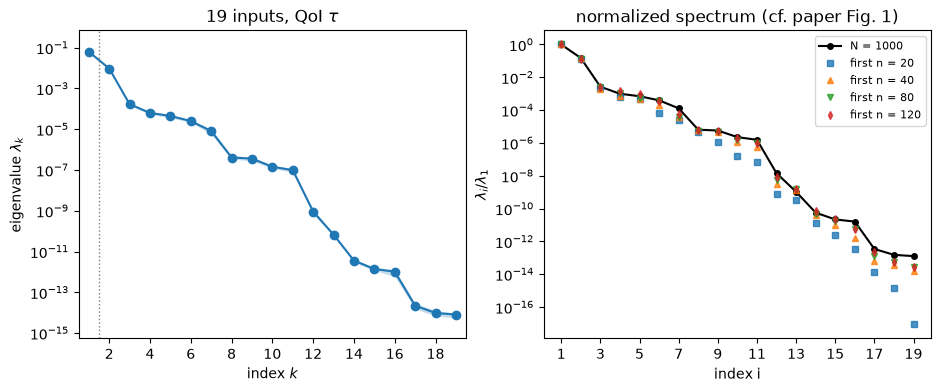

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub19, ax=axes[0])
axes[0].set_title(r'19 inputs, QoI $\tau$')
Gn19 = G19 * (hm.UPPER19 - hm.LOWER19) / 2
def spectrum(Gn):
    return np.sort(np.linalg.eigvalsh(Gn.T @ Gn / len(Gn)))[::-1]
lamN = spectrum(Gn19)
axes[1].semilogy(np.arange(1, 20), lamN / lamN[0], 'k-o', ms=4, label='N = 1000')
for n_, mk in zip([20, 40, 80, 120], ['s', '^', 'v', 'd']):
    l_ = spectrum(Gn19[:n_])
    axes[1].semilogy(np.arange(1, 20), l_ / l_[0], mk, ms=4, alpha=.8, label=f'first n = {n_}')
axes[1].set_xlabel('index i'); axes[1].set_ylabel(r'$\lambda_i/\lambda_1$')
axes[1].set_title('normalized spectrum (cf. paper Fig. 1)'); axes[1].legend(fontsize=8)
axes[1].set_xticks(range(1, 20, 2))
plt.close(fig)
lam = sub19.eigenvalues
print('lambda_i/lambda_1, N = 1000:', np.array2string((lam / lam[0])[:6], precision=4))
for n_ in [20, 40, 80, 120]:
    l_ = spectrum(Gn19[:n_])
    print(f'first {n_:3d} samples: lambda_i/lambda_1 =', np.array2string((l_ / l_[0])[:4], precision=4))
fig

For $\tau$, $\lambda_1/\lambda_2 = 6.7$ ($\lambda_2/\lambda_1 = 0.150$), followed by a much larger drop, $\lambda_2/\lambda_3 = 56.2$. Together the first two eigenvalues hold 99.6 % of the trace ($\lambda_1$ alone holds 86.6 %). The paper reports $\lambda_1$ "roughly an order of magnitude larger than $\lambda_2$". The gap rule picks $n = 1$. For $\ln\tau$ the first gap is much larger, $\lambda_1/\lambda_2 = 76.9$, and $\lambda_1$ holds 98.3 % of the trace. As in the paper, 20 samples already give the leading eigenvalues: $\lambda_2/\lambda_1$ is 0.130, 0.148, 0.130 and 0.127 from the first 20, 40, 80 and 120 samples, against 0.150 from all 1000. The smallest eigenvalue is $1.28\times10^{-13}\lambda_1$ (printed below). Six reactions barely affect $\tau$: R4–R8 (the dissociation and recombination reactions) and R18 have mean squared normalized derivatives below $10^{-6}\lambda_1$ (printed below).

**Subspace errors.** The bootstrap mean distance between the estimated and resampled subspaces:

bootstrap mean subspace distance, k = 1..6: [0.021 0.009 0.055 0.141 0.113 0.069]
(lambda1 + lambda2) / trace = 0.9957; smallest eigenvalue lambda19/lambda1 = 1.28e-13
inputs with E[(dtau/dx_i)^2] < 1e-6 lambda1 (6): A4 2e-13, A5 3e-11, A6 1e-13, A7 6e-13, A8 6e-11, A18 7e-08


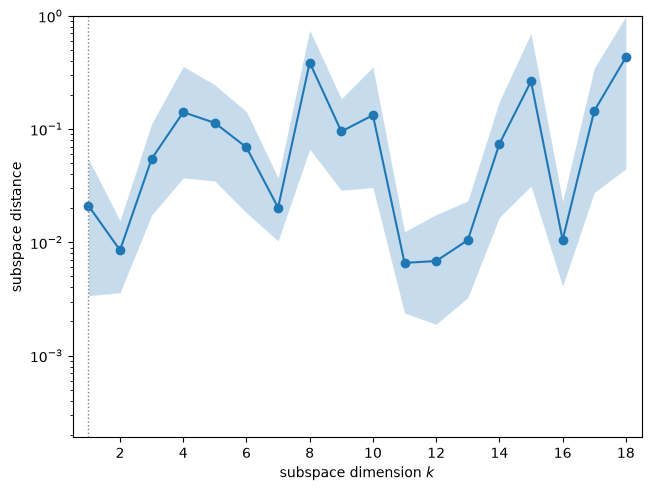

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub19)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:',
      np.array2string(sub19.bootstrap_distances.mean(axis=0)[:6], precision=3))
lam = sub19.eigenvalues
print(f'(lambda1 + lambda2) / trace = {(lam[0] + lam[1]) / lam.sum():.4f}; '
      f'smallest eigenvalue lambda19/lambda1 = {lam[-1] / lam[0]:.2e}')
msg = np.mean(Gn19**2, axis=0) / lam[0]                  # E[(dtau/dx_i)^2] / lambda1, normalized x
quiet = np.where(msg < 1e-6)[0]
print(f'inputs with E[(dtau/dx_i)^2] < 1e-6 lambda1 ({len(quiet)}):',
      ', '.join(f'A{i + 1} {msg[i]:.0e}' for i in quiet))
fig

The one-dimensional subspace is well determined (mean bootstrap distance 0.021 for $k = 1$; 0.009 for $k = 2$, the subspace behind the sharper gap).

**First eigenvector and activity scores.** With a single active direction, the normalized activity score of input $i$ is $\tilde\nu_{i,1} = w_{1,i}^2$ (paper Remark 3.1). The paper plots squared components and activity scores in its Figs. 2 (left) and 3. Sign rule: the $A_9$ component is positive.

w1 (A9 > 0): A9 +0.670, A1 -0.487, A15 -0.398, A17 -0.359, A14 +0.156, A11 -0.056, A16 +0.013, A10 -0.005
activity scores w1^2: A9 0.448, A1 0.237, A15 0.158, A17 0.129, A14 0.024, A11 0.003 ; the other 13 sum to 2.3e-04
|w1(tau) . w1(ln tau)| = 0.8603
Eq. (12) with the first  20 gradient samples: eps = 0.2461
Eq. (12) with the first  40 gradient samples: eps = 0.2193
Eq. (12) with the first  45 gradient samples: eps = 0.2101
Eq. (12) with the first  80 gradient samples: eps = 0.1788
Eq. (12) with the first 120 gradient samples: eps = 0.1787


regression approach (local linear gradients from the first 900 values of tau): eps = 0.1414, lambda1/lambda2 = 18.2


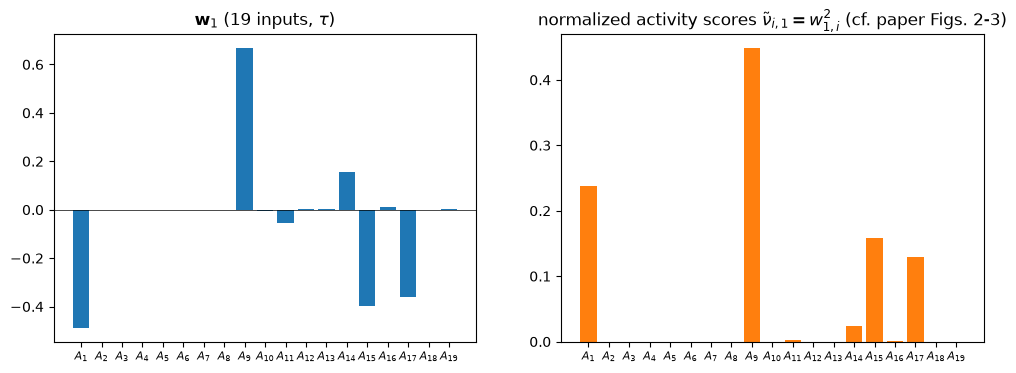

In [9]:
w19 = sub19.W[:, 0] * np.sign(sub19.W[8, 0])         # sign rule: the A9 component positive
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, 20), w19, color='C0')
axes[0].set_xticks(range(1, 20)); axes[0].set_xticklabels(lab19, fontsize=8)
axes[0].axhline(0, color='k', lw=.5); axes[0].set_title(r'$\mathbf{w}_1$ (19 inputs, $\tau$)')
axes[1].bar(range(1, 20), w19**2, color='C1')
axes[1].set_xticks(range(1, 20)); axes[1].set_xticklabels(lab19, fontsize=8)
axes[1].set_title(r'normalized activity scores $\tilde\nu_{i,1} = w_{1,i}^2$ (cf. paper Figs. 2-3)')
plt.close(fig)
order = np.argsort(-w19**2)
print('w1 (A9 > 0):', ', '.join(f'A{i + 1} {w19[i]:+.3f}' for i in order[:8]))
print('activity scores w1^2:', ', '.join(f'A{i + 1} {w19[i]**2:.3f}' for i in order[:6]),
      f'; the other 13 sum to {np.sum(w19[order[6:]]**2):.1e}')
wL = subL19.W[:, 0] * np.sign(subL19.W[8, 0])
print(f'|w1(tau) . w1(ln tau)| = {abs(w19 @ wL):.4f}')
# paper Eq. (12): relative L2 difference of the squared components, N = 1000 vs n samples
def eps(wn, wN=w19):
    return np.linalg.norm(wN**2 - wn**2) / np.linalg.norm(wN**2)
def w1_of(Gn):
    return np.linalg.eigh(Gn.T @ Gn / len(Gn))[1][:, -1]
for n_ in [20, 40, 45, 80, 120]:
    print(f'Eq. (12) with the first {n_:3d} gradient samples: eps = {eps(w1_of(Gn19[:n_])):.4f}')
ll = ac.local_linear_gradients(X=X19[:900], f=f19[:900], space=space19)
sub_ll = ac.active_subspace(space=space19, X=X19[:900], grads=ll, estimator='as', n=1)
print(f'regression approach (local linear gradients from the first 900 values of tau): '
      f'eps = {eps(sub_ll.W[:, 0]):.4f}, lambda1/lambda2 = {sub_ll.eigenvalues[0] / sub_ll.eigenvalues[1]:.1f}')
fig

The active direction is a contrast between chain termination and chain branching. $A_9$ (H + O$_2$ + M → HO$_2$ + M) has $w_{1,9} = +0.670$, and $A_1$ (H + O$_2$ → O + OH) has $-0.487$. $A_{15}$ (H$_2$O$_2$ + M → 2 OH + M) and $A_{17}$ (H$_2$O$_2$ + H → H$_2$ + HO$_2$) follow at $-0.398$ and $-0.359$. The activity scores are 0.448, 0.237, 0.158 and 0.129, then 0.024 for $A_{14}$ and 0.003 for $A_{11}$; the other 13 sum to $2.3\times10^{-4}$. This is the paper's ranking: "largely due to the uncertainty in $A_9$ while $A_1$, $A_{15}$, and $A_{17}$ are also observed to contribute significantly". The first eigenvector of $\ln\tau$ is mostly $A_9$ and $A_1$ ($|\mathbf w_1(\tau)\cdot\mathbf w_1(\ln\tau)| = 0.860$).

The paper measures convergence by its Eq. (12), the relative 2-norm difference of the squared components from $N = 1000$ and from $n$ samples. It reports $\mathcal O(10^{-2})$ for $n = 20$–120, and 0.0657 at 45 samples. Here Eq. (12) gives 0.246, 0.219, 0.210, 0.179 and 0.179 for the first 20, 40, 45, 80 and 120 samples, 3.2 times the paper's value at 45 samples. The likely reason is that our $\lambda_2$ is close enough to $\lambda_1$ that $\mathbf w_1$ moves within the two-dimensional dominant subspace. The paper's regression approach (local linear gradients from 900 function values) gives 0.141 here, against the paper's 0.1050.

**Sufficient summary plots** (cf. the paper's Fig. 2, right). Left: $\tau$ against $y_1 = \mathbf w_1^T\mathbf x$, with a cubic fit. Right: $\ln\tau$ against its own active variable.

LOO R^2, 19 inputs: tau quadratic in y 0.9006, cubic 0.9033; ln tau cubic in its own y 0.9263


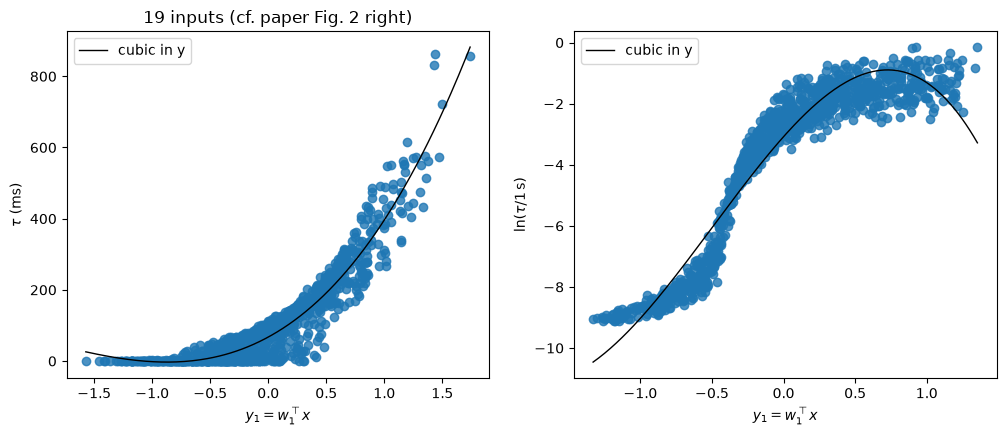

In [10]:
sur19_2 = ac.fit_surrogate(X=X19, f=f19, subspace=sub19, kind='poly', degree=2)
sur19_3 = ac.fit_surrogate(X=X19, f=f19, subspace=sub19, kind='poly', degree=3)
surL19_3 = ac.fit_surrogate(X=X19, f=np.log(f19), subspace=subL19, kind='poly', degree=3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub19, X=X19, f=f19 * 1e3, dims=1, qoi_label=r'$\tau$ (ms)', ax=axes[0])
ac.plotting.plot_sufficient_summary(subL19, X=X19, f=np.log(f19), dims=1, qoi_label=r'$\ln(\tau/1\,\mathrm{s})$', ax=axes[1])
y19 = space19.to_normalized(X19) @ sub19.W[:, 0]
yy = np.linspace(y19.min(), y19.max(), 200)
axes[0].plot(yy, 1e3 * sur19_3.evaluate(yy[:, None]), 'k-', lw=1, label='cubic in y')
axes[0].legend(); axes[0].set_title('19 inputs (cf. paper Fig. 2 right)')
yL = space19.to_normalized(X19) @ subL19.W[:, 0]
yyL = np.linspace(yL.min(), yL.max(), 200)
axes[1].plot(yyL, surL19_3.evaluate(yyL[:, None]), 'k-', lw=1, label='cubic in y'); axes[1].legend()
plt.close(fig)
print(f'LOO R^2, 19 inputs: tau quadratic in y {sur19_2.loo_r_squared:.4f}, cubic {sur19_3.loo_r_squared:.4f}; '
      f'ln tau cubic in its own y {surL19_3.loo_r_squared:.4f}')
fig

$\tau$ is a convex, rapidly rising function of $y_1$, with clear scatter on the slow branch. The quadratic and cubic in $y_1$ have leave-one-out $R^2$ = 0.9006 and 0.9033. On the log scale the two branches are plain to see: a plateau near $\ln\tau \approx -9$ ($\tau \approx 0.1$ ms), a steep transition near $y_1 \approx -0.4$, and the slow branch above. A cubic in $y_1$ cannot follow the step (LOO $R^2$ = 0.9263).

**Two active variables for $\tau$.** The sharper gap after $\lambda_2$ suggests a two-dimensional subspace. The summary plot on $(y_1, y_2)$ and a cubic in both:

w2 (largest component positive): A15 +0.635, A17 +0.488, A9 +0.470, A1 -0.299, A14 -0.213, A10 +0.032
LOO R^2, tau cubic in (y1, y2): 0.9766


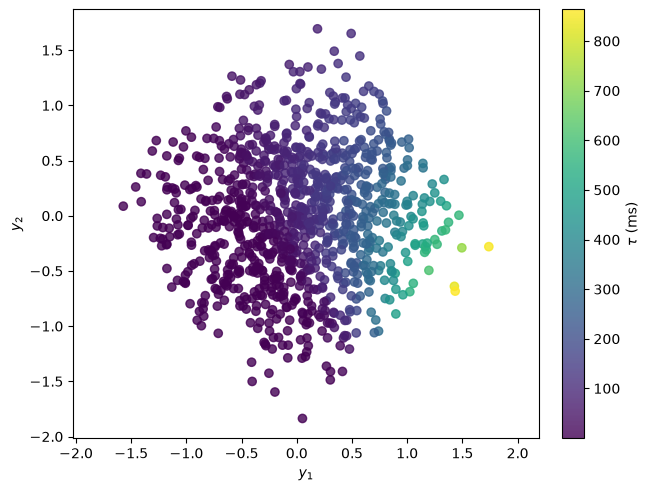

In [11]:
sub19_n2 = ac.active_subspace(space=space19, X=X19, f=f19, grads=G19, estimator='as', n=2)
sur19_2d = ac.fit_surrogate(X=X19, f=f19, subspace=sub19_n2, kind='poly', degree=3)
W2 = sub19_n2.W[:, :2]
fig, ax = ac.plotting.plot_sufficient_summary(sub19_n2, X=X19, f=f19 * 1e3, dims=2, qoi_label=r'$\tau$ (ms)')
plt.close(fig)
w2 = W2[:, 1] * np.sign(W2[np.argmax(np.abs(W2[:, 1])), 1])
o2 = np.argsort(-w2**2)
print('w2 (largest component positive):', ', '.join(f'A{i + 1} {w2[i]:+.3f}' for i in o2[:6]))
print(f'LOO R^2, tau cubic in (y1, y2): {sur19_2d.loo_r_squared:.4f}')
fig

The second direction is dominated by the H$_2$O$_2$ reactions, $A_{15}$ (+0.635) and $A_{17}$ (+0.488), together with $A_9$ (+0.470). It describes the slow branch, whose rate is set by H$_2$O$_2$ decomposition. A cubic in $(y_1, y_2)$ reaches leave-one-out $R^2 = 0.9766$, against 0.9033 for the cubic in $y_1$ alone.

### Results: 36 inputs (pre-exponentials, activation energies, initial state)

The same estimator on the 36-input set (paper Sec. 5): eigenvalues (left) and bootstrap subspace distances (right).

36 inputs, tau   : eigenvalues [4.204e-02 4.383e-03 4.087e-05 2.090e-05 9.155e-06 7.720e-06] ...; lambda1/lambda2 = 9.6, lambda2/lambda3 = 107.23, lambda1/sum = 0.904; gap rule picks n = 1
36 inputs, ln tau: eigenvalues [1.921e+01 3.581e-01 3.536e-02 7.672e-03 3.956e-03 9.915e-04] ...; lambda1/lambda2 = 53.6, lambda2/lambda3 = 10.13, lambda1/sum = 0.979; gap rule picks n = 1
bootstrap mean subspace distance, k = 1..6: [0.015 0.006 0.072 0.072 0.255 0.053]


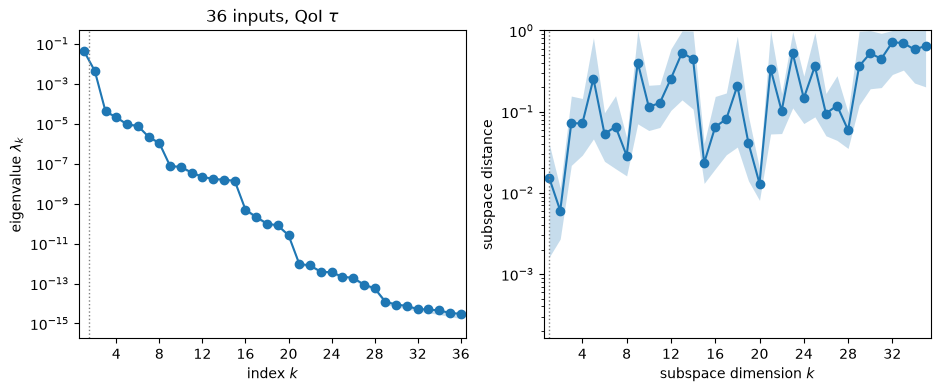

In [12]:
space36 = ac.Uniform(hm.LOWER36, hm.UPPER36, names=hm.NAMES36)
sub36 = ac.active_subspace(space=space36, X=X36, f=f36, grads=G36, estimator='as', n=1,
                           nboot=500, rng=SEED)
subL36 = ac.active_subspace(space=space36, X=X36, f=np.log(f36), grads=G36 / f36[:, None],
                            estimator='as', n=1, nboot=500, rng=SEED)
for name, s in [('tau', sub36), ('ln tau', subL36)]:
    lam = s.eigenvalues
    k_hat = ac.dimension_criterion(s, rule='evg')[2]
    print(f'36 inputs, {name:6s}: eigenvalues {np.array2string(lam[:6], precision=3)} ...; '
          f'lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.2f}, '
          f'lambda1/sum = {lam[0] / lam.sum():.3f}; gap rule picks n = {k_hat}')
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub36, ax=axes[0]); axes[0].set_title(r'36 inputs, QoI $\tau$')
ac.plotting.plot_subspace_errors(sub36, ax=axes[1])
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:',
      np.array2string(sub36.bootstrap_distances.mean(axis=0)[:6], precision=3))
fig

For $\tau$, $\lambda_1/\lambda_2 = 9.6$, again with a sharper second gap ($\lambda_2/\lambda_3 = 107.2$), and $\lambda_1$ holds 90.4 % of the trace. For $\ln\tau$, $\lambda_1/\lambda_2 = 53.6$. The gap rule picks $n = 1$ in both cases. The bootstrap mean distance is 0.015 for $k = 1$ and 0.006 for $k = 2$.

**First eigenvector and activity scores** (cf. paper Fig. 4 left and Fig. 7):

w1 (A9 > 0): lnA9 +0.607, T0 -0.452, lnA1 -0.435, lnA15 -0.296, lnA17 -0.285, Ea15 +0.192, lnA14 +0.125, Ea1 +0.112
activity scores w1^2: lnA9 0.368, T0 0.204, lnA1 0.189, lnA15 0.087, lnA17 0.081, Ea15 0.037, lnA14 0.016, Ea1 0.013 ; the other 28 sum to 0.005
P0 and phi: P0 0.0000, phi 0.0000
|w1(36)[A] . w1(19)| / |w1(36)[A]| = 0.9973
R4 (written O + H2O <=> 2 OH): E[(dtau/dx_i)^2] / lambda1 = lnA4 9e-14, Ea4 1e-13 ; w1 components -2e-08, -4e-09


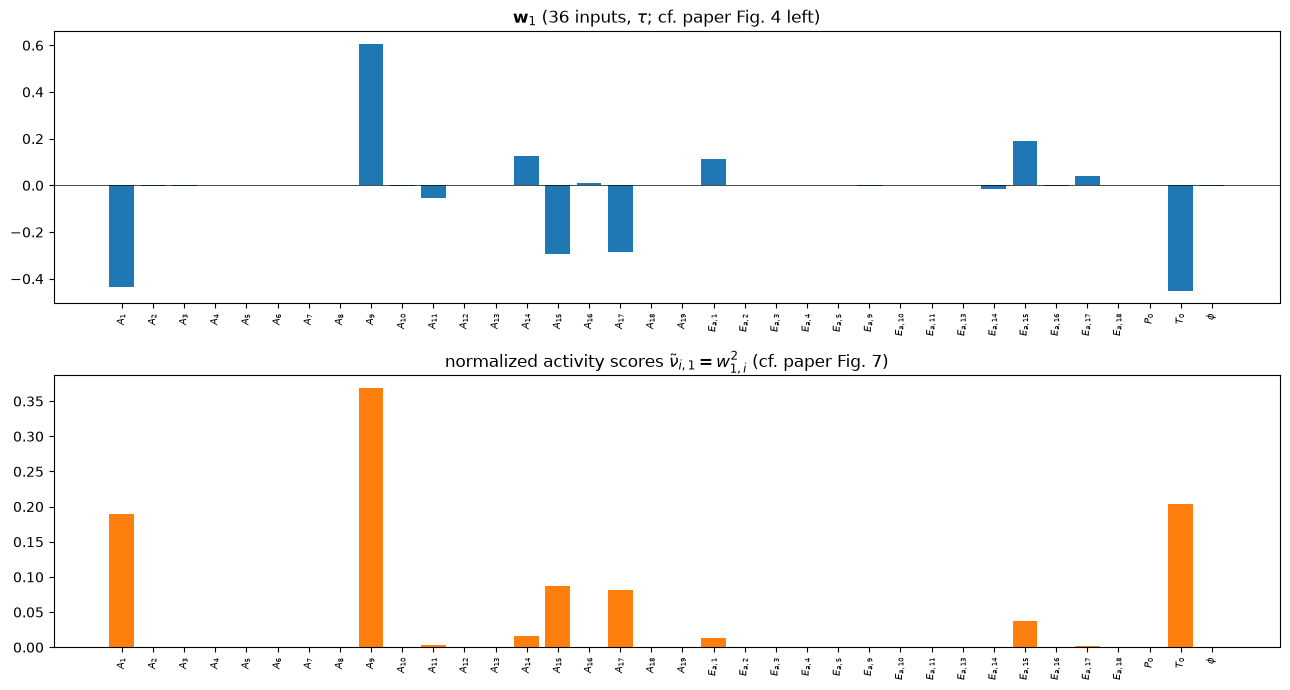

In [13]:
w36 = sub36.W[:, 0] * np.sign(sub36.W[8, 0])         # sign rule: A9 component positive
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
axes[0].bar(range(36), w36, color='C0'); axes[0].axhline(0, color='k', lw=.5)
axes[0].set_title(r'$\mathbf{w}_1$ (36 inputs, $\tau$; cf. paper Fig. 4 left)')
axes[1].bar(range(36), w36**2, color='C1')
axes[1].set_title(r'normalized activity scores $\tilde\nu_{i,1} = w_{1,i}^2$ (cf. paper Fig. 7)')
for a in axes:
    a.set_xticks(range(36)); a.set_xticklabels(lab36, fontsize=7, rotation=90)
fig.tight_layout(); plt.close(fig)
order = np.argsort(-w36**2)
print('w1 (A9 > 0):', ', '.join(f'{hm.NAMES36[i]} {w36[i]:+.3f}' for i in order[:8]))
print('activity scores w1^2:', ', '.join(f'{hm.NAMES36[i]} {w36[i]**2:.3f}' for i in order[:8]),
      f'; the other 28 sum to {np.sum(w36[order[8:]]**2):.3f}')
print('P0 and phi:', ', '.join(f'{n} {w36[hm.NAMES36.index(n)]**2:.4f}' for n in ['P0', 'phi']))
print(f'|w1(36)[A] . w1(19)| / |w1(36)[A]| = {abs(w36[:19] @ w19) / np.linalg.norm(w36[:19]):.4f}')
msg36 = np.mean((G36 * (hm.UPPER36 - hm.LOWER36) / 2)**2, axis=0) / sub36.eigenvalues[0]
j4 = [hm.NAMES36.index(n) for n in ['lnA4', 'Ea4']]
print('R4 (written O + H2O <=> 2 OH): E[(dtau/dx_i)^2] / lambda1 =',
      ', '.join(f'{hm.NAMES36[j]} {msg36[j]:.0e}' for j in j4),
      '; w1 components', ', '.join(f'{w36[j]:+.0e}' for j in j4))
fig

The largest activity scores are those of $\ln A_9$ (0.368), $T_0$ (0.204), $\ln A_1$ (0.189), $\ln A_{15}$ (0.087), $\ln A_{17}$ (0.081) and $E_{a,15}$ (0.037). $P_0$ and $\phi_0$ score below $5\times10^{-5}$, and the 28 inputs after the top eight sum to 0.005. The paper reaches the same conclusion from its activity scores and total Sobol' indices (text p. 159, Fig. 7 p. 160): "the variability in the ignition delay is predominantly due to the uncertainty in $A_1$, $A_9$, and $T_0$ while contributions from the uncertainty in $A_{15}$, $A_{17}$, and $E_{a,15}$ [...] are also found to be significant", and $P_0$ and $\phi_0$ "do not seem to impact the ignition delay". Restricted to the 19 pre-exponentials, $\mathbf w_1$ is the 19-input direction ($|\cos| = 0.997$). The ±2 % intervals on $\ln A$ are narrower than the ±3 % above, and $T_0$ takes a share. R4, written here in the opposite direction to the paper's Table 1, is negligible: $\mathbb E[(\partial\tau/\partial x_i)^2]/\lambda_1$ is $9\times10^{-14}$ for $\ln A_4$ and $1\times10^{-13}$ for $E_{a,4}$.

**Sufficient summary plots** (cf. paper Fig. 5, which fits a quadratic and a cubic):

LOO R^2, 36 inputs: tau quadratic in y 0.9338, cubic 0.9352; ln tau cubic in its own y 0.9278


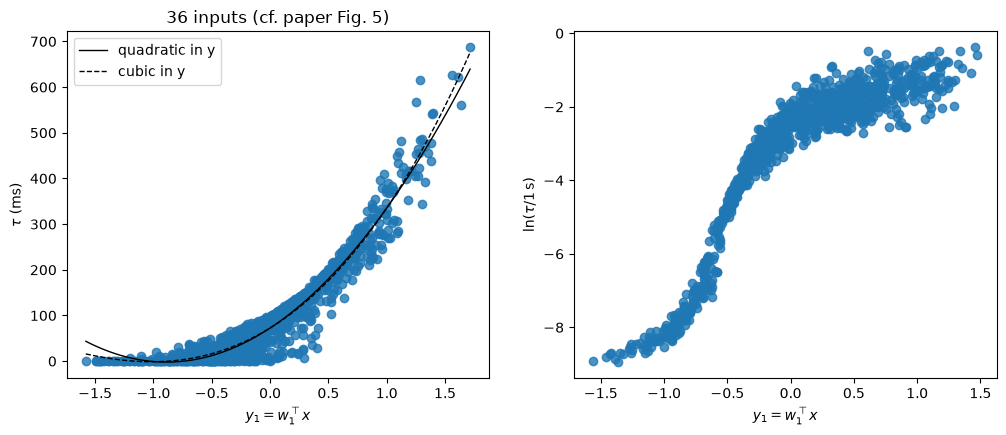

In [14]:
sur36_2 = ac.fit_surrogate(X=X36, f=f36, subspace=sub36, kind='poly', degree=2)
sur36_3 = ac.fit_surrogate(X=X36, f=f36, subspace=sub36, kind='poly', degree=3)
surL36_3 = ac.fit_surrogate(X=X36, f=np.log(f36), subspace=subL36, kind='poly', degree=3)
y36 = space36.to_normalized(X36) @ sub36.W[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub36, X=X36, f=f36 * 1e3, dims=1, qoi_label=r'$\tau$ (ms)', ax=axes[0])
yy = np.linspace(y36.min(), y36.max(), 200)
axes[0].plot(yy, 1e3 * sur36_2.evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in y')
axes[0].plot(yy, 1e3 * sur36_3.evaluate(yy[:, None]), 'k--', lw=1, label='cubic in y')
axes[0].legend(); axes[0].set_title('36 inputs (cf. paper Fig. 5)')
ac.plotting.plot_sufficient_summary(subL36, X=X36, f=np.log(f36), dims=1, qoi_label=r'$\ln(\tau/1\,\mathrm{s})$', ax=axes[1])
plt.close(fig)
print(f'LOO R^2, 36 inputs: tau quadratic in y {sur36_2.loo_r_squared:.4f}, cubic {sur36_3.loo_r_squared:.4f}; '
      f'ln tau cubic in its own y {surL36_3.loo_r_squared:.4f}')
fig

The quadratic and cubic in $y_1$ reach leave-one-out $R^2$ = 0.9338 and 0.9352, and the $\ln\tau$ plot shows the same two branches as before.

**Surrogate assessment** (cf. paper Table 2 and Fig. 6). We evaluate the model and the one-dimensional surrogates (fitted to the 1000 gradient samples) on the 10 000 further Monte Carlo samples, and compare means and standard deviations with 95 % bootstrap intervals.

model, 10^4 MC samples           mean 0.1067 s [0.1045, 0.1089], sd 0.1109 s [0.1083, 0.1134]


quadratic surrogate in y         mean 0.1043 s [0.1023, 0.1064], sd 0.1054 s [0.1033, 0.1075]


cubic surrogate in y             mean 0.1044 s [0.1024, 0.1065], sd 0.1049 s [0.1027, 0.1071]
validation R^2 on the 10^4 MC samples, quadratic surrogate in y: 0.9323
validation R^2 on the 10^4 MC samples, cubic surrogate in y: 0.9343
surrogate values below the smallest model value (1.19e-04 s; drawn in the first bin): quadratic 723 (692 negative), cubic 531 (507 negative); model range 0.12-926 ms, 1457 model values below 2 ms


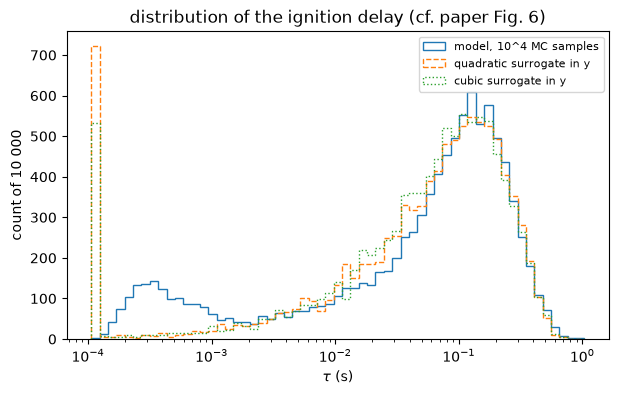

In [15]:
def mean_sd_ci(v, nb=2000, rng=np.random.default_rng(SEED)):
    idx = rng.integers(0, len(v), (nb, len(v)))
    m_, s_ = v[idx].mean(1), v[idx].std(1, ddof=1)
    return v.mean(), v.std(ddof=1), np.percentile(m_, [2.5, 97.5]), np.percentile(s_, [2.5, 97.5])
rows = [('model, 10^4 MC samples', fmc),
        ('quadratic surrogate in y', ac.predict(sur36_2, Xmc)),
        ('cubic surrogate in y', ac.predict(sur36_3, Xmc))]
stats = {}
for name, v in rows:
    m_, s_, cm, cs = mean_sd_ci(v)
    stats[name] = (m_, s_)
    print(f'{name:32s} mean {m_:.4f} s [{cm[0]:.4f}, {cm[1]:.4f}], sd {s_:.4f} s [{cs[0]:.4f}, {cs[1]:.4f}]')
for name, v in rows[1:]:
    r2 = 1 - np.sum((v - fmc)**2) / np.sum((fmc - fmc.mean())**2)
    print(f'validation R^2 on the 10^4 MC samples, {name}: {r2:.4f}')
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.logspace(np.log10(fmc.min()) - .05, np.log10(fmc.max()) + .05, 60)
for (name, v), ls in zip(rows, ['-', '--', ':']):
    ax.hist(np.clip(v, bins[0], None), bins=bins, histtype='step', ls=ls, density=False, label=name)
ax.set_xscale('log'); ax.set_xlabel(r'$\tau$ (s)'); ax.set_ylabel('count of 10 000')
ax.set_title('distribution of the ignition delay (cf. paper Fig. 6)'); ax.legend(fontsize=8)
plt.close(fig)
print(f'surrogate values below the smallest model value ({fmc.min():.2e} s; drawn in the first bin): quadratic '
      f'{np.sum(rows[1][1] < fmc.min())} ({np.sum(rows[1][1] <= 0)} negative), cubic '
      f'{np.sum(rows[2][1] < fmc.min())} ({np.sum(rows[2][1] <= 0)} negative); '
      f'model range {fmc.min() * 1e3:.2f}-{fmc.max() * 1e3:.0f} ms, {np.sum(fmc < 2e-3)} model values below 2 ms')
fig

On the 10 000 validation samples the model has mean 0.1067 s (95 % bootstrap interval [0.1045, 0.1089]) and standard deviation 0.1109 s ([0.1083, 0.1134]). The quadratic and cubic surrogates in $y_1$ give 0.1043 and 0.1044 s for the mean and 0.1054 and 0.1049 s for the standard deviation. Their intervals overlap the model's for the mean, but the standard deviation is 5.0–5.4 % low. Their validation $R^2$ is 0.9323 and 0.9343, close to the leave-one-out values. The histogram shows where they fail. The fast branch (1457 of the 10 000 model values are below 2 ms) is a separate mode near 0.1–1 ms. The surrogates cannot produce it: 692 (quadratic) and 507 (cubic) of their values are negative and are drawn in the first bin. The paper's PDFs (Fig. 6) run from about 2 ms to 400 ms, with no fast mode. With its mechanism, the paper's samples probably stayed on the slow branch, and the fast mode is a consequence of the Li et al. rates (next section).

### Comparison with the paper

The cell prints the notebook values used in the table.

In [16]:
lam19, lam36 = sub19.eigenvalues, sub36.eigenvalues
top = lambda w, names, k: ', '.join(names[i] for i in np.argsort(-w**2)[:k])
print(f'19: lambda1/lambda2 {lam19[0] / lam19[1]:.1f}; top-4 activity {top(w19, hm.NAMES19, 4)}')
print(f'36: lambda1/lambda2 {lam36[0] / lam36[1]:.1f}; top-6 activity {top(w36, hm.NAMES36, 6)}')
print(f'tau at the nominal point: 86.13 ms (generate_data.py / DATA.md; Cantera needed to recompute)')

19: lambda1/lambda2 6.7; top-4 activity lnA9, lnA1, lnA15, lnA17
36: lambda1/lambda2 9.6; top-6 activity lnA9, T0, lnA1, lnA15, lnA17, Ea15
tau at the nominal point: 86.13 ms (generate_data.py / DATA.md; Cantera needed to recompute)


| Quantity | Paper value | Notebook value |
|---|---|---|
| Mechanism and solver | Yetter et al. (1991) rates, TChem [1, p. 153] | Li et al. (2004) rates, same 19 reactions (R4 written in reverse, O + H$_2$O ⇌ 2 OH), Cantera 3.2.0 |
| Ignition criterion | $dT/dt$ above an unstated threshold | $T = T_0 + 400$ K |
| $\tau$ at the nominal point | not reported | 86.13 ms |
| 19 inputs: $\lambda_1$ vs $\lambda_2$ | "roughly an order of magnitude" (p. 157; Fig. 1, p. 156) | $\lambda_1/\lambda_2 = 6.7$; $\lambda_2/\lambda_3 = 56.2$ |
| 19 inputs: leading spectrum from 20 samples | "approximated reasonably well" (Fig. 1) | $\lambda_2/\lambda_1$ = 0.130 (first 20) vs 0.150 (1000) |
| 19 inputs: Eq. (12), squared $\mathbf w_1$, $n$ vs $N = 1000$ | $\mathcal O(10^{-2})$ for $n$ = 20–120; 0.0657 at 45 samples (p. 157) | 0.246 ($n$ = 20) to 0.179 ($n$ = 120); 0.210 at 45 |
| 19 inputs: Eq. (12), regression approach, 900 runs | 0.1050 | 0.141 (local linear gradients, first 900 values) |
| 19 inputs: ranking of activity scores | $A_9$, then $A_1$, $A_{15}$, $A_{17}$ (p. 157; Fig. 3, p. 158) | $A_9$ 0.448, $A_1$ 0.237, $A_{15}$ 0.158, $A_{17}$ 0.129 |
| 19 inputs: one-dimensional summary | "can be approximated by a 1-dimensional active subspace" (Fig. 2) | LOO $R^2$ 0.9006 (quadratic), 0.9033 (cubic); 0.9766 for a cubic in two variables |
| 36 inputs: dimension | 1 (Figs. 4–5) | gap rule $n = 1$; $\lambda_1/\lambda_2 = 9.6$, $\lambda_2/\lambda_3 = 107.2$ |
| 36 inputs: runs to converge (Alg. 1, tolerance 0.05) | 925 (finite differences), 1850 (regression) | not computed (1000 gradient samples, 73 000 runs) |
| 36 inputs: important inputs | $A_1$, $A_9$, $T_0$; then $A_{15}$, $A_{17}$, $E_{a,15}$; $P_0$, $\phi_0$ unimportant (p. 159; Fig. 7, p. 160) | $A_9$ 0.368, $T_0$ 0.204, $A_1$ 0.189, $A_{15}$ 0.087, $A_{17}$ 0.081, $E_{a,15}$ 0.037; $P_0$, $\phi_0$ < $5\times10^{-5}$ |
| 36 inputs: surrogate | quadratic (finite differences), cubic (regression) in $y_1$ (Fig. 5) | LOO $R^2$ 0.9338 (quadratic), 0.9352 (cubic) |
| Table 2: model mean, sd of $\tau$ ($10^4$ samples; s) | 0.15, 0.14 | 0.1067, 0.1109 |
| Table 2: surrogate mean, sd (s) | 0.15, 0.13 (both approaches) | 0.1043, 0.1054 (quadratic); 0.1044, 0.1049 (cubic) |
| Range of $\tau$ (Fig. 6, p. 159) | "from about 2 ms to 400 ms" | 0.12–926 ms; 2.5–97.5 % range 0.238–399 ms; 1457 of $10^4$ below 2 ms |
| Total Sobol' indices (Fig. 7) | computed from the surrogate | not computed |

**What agrees.** Both studies find a dominant first direction. Both rank the inputs the same way, within the 19-input case and among the 36 inputs, with $P_0$ and $\phi_0$ negligible. Both find that 20 gradient samples already give the leading eigenvalues. Quadratic and cubic surrogates in $y_1$ reproduce the mean of $\tau$ to within 2.3 % and its standard deviation to within 5.4 %; the paper's are within 0.01 s.

**What differs, and why.** The paper's Table 2 units are not stated. Fig. 6's range implies seconds, which we assume. Our $\tau$ is about 30 % shorter on average (0.107 s against 0.15 s), our first gaps are smaller (6.7 and 9.6), and our Eq. (12) errors are larger (0.210 against 0.0657 at 45 samples, 3.2 times). All three follow from the mechanism. At 900 K and 1 atm a fuel-rich H$_2$/O$_2$ mixture sits at the second explosion limit, where $\tau$ depends steeply on the ratio of the branching rate $k_1$ to the termination rate $k_9[\mathrm M]$. With the Li et al. rates (R9 in falloff form, with its own third-body efficiencies), the paper's ranges reach across that limit. 23 % of the 19-input samples and 11–12 % of the 36-input samples (114 of 1000; 1239 of 10 000) land on the fast branch, which the paper's Fig. 6 does not show. That adds the second direction ($A_{15}$, $A_{17}$: the slow branch) and makes $\mathbf w_1$ harder to pin down from few samples. We cannot test this without the Yetter et al. parameters, so it remains a hypothesis. A second, smaller effect: the width of the paper's $\pm3$ % interval on $\ln A$ depends on the units and magnitude of $A^*$, so different nominal values give different uncertainty factors for the same reaction. For R9, taking the low-pressure $A_9^*$ raises the fast fraction that the threshold rule predicts from 0.149 to 0.214.

### References

[1] M. Vohra, A. Alexanderian, H. Guy, and S. Mahadevan. [Active subspace-based dimension reduction for chemical kinetics applications with epistemic uncertainty](https://doi.org/10.1016/j.combustflame.2019.03.006). *Combustion and Flame*, 204:152–161, 2019. (Preprint: arXiv:1810.00955.)

[2] J. Li, Z. Zhao, A. Kazakov, and F. L. Dryer. [An updated comprehensive kinetic model of hydrogen combustion](https://doi.org/10.1002/kin.20026). *International Journal of Chemical Kinetics*, 36(10):566–575, 2004.

[3] R. A. Yetter, F. L. Dryer, and H. Rabitz. A comprehensive reaction mechanism for carbon monoxide/hydrogen/oxygen kinetics. *Combustion Science and Technology*, 79:97–128, 1991. (The paper's mechanism; not read for this notebook, and its DOI could not be confirmed on Crossref.)

[4] M. Vohra, A. Alexanderian, C. Safta, and S. Mahadevan. [Sensitivity-driven adaptive construction of reduced-space surrogates](https://doi.org/10.1007/s10915-018-0894-4). *Journal of Scientific Computing*, 79(2):1335–1359, 2019. (Same H2/O2 problem; defines the ignition delay as the inflection point of the temperature history.)

[5] D. G. Goodwin, H. K. Moffat, I. Schoegl, R. L. Speth, and B. W. Weber. Cantera: An object-oriented software toolkit for chemical kinetics, thermodynamics, and transport processes. Version 3.2.0, https://www.cantera.org.

[6] G. P. Smith et al. GRI-Mech 3.0, http://combustion.berkeley.edu/gri-mech/ (source of the thermodynamic data, via Cantera's `h2o2.yaml`).

[7] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[8] P. G. Constantine, E. Dow, and Q. Wang. [Active subspace methods in theory and practice: applications to kriging surfaces](https://doi.org/10.1137/130916138). *SIAM Journal on Scientific Computing*, 36(4):A1500–A1524, 2014.

[R1]: https://doi.org/10.1016/j.combustflame.2019.03.006

### Acknowledgments (from the paper)

M. Vohra and S. Mahadevan acknowledge funding from the National Science Foundation (Grant No. 1404823, CDSE Program) and Sandia National Laboratories (PO No. 1643376). The research of A. Alexanderian was partially supported by the National Science Foundation through grant DMS-1745654. The authors thank C. Safta (Sandia) for guidance with TChem.

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 11.1 s
